In [1]:
import pandas as pd

df = pd.read_csv("../data/iris.csv")

df.head()

print("Dataset Shape:", df.shape)

print("\nDataset Columns:")
print(df.columns.tolist())

print("\nSpecies Distribution:")
print(df["species"].value_counts())


Dataset Shape: (150, 5)

Dataset Columns:
['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

Species Distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


In [4]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


In [5]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 1


In [6]:
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


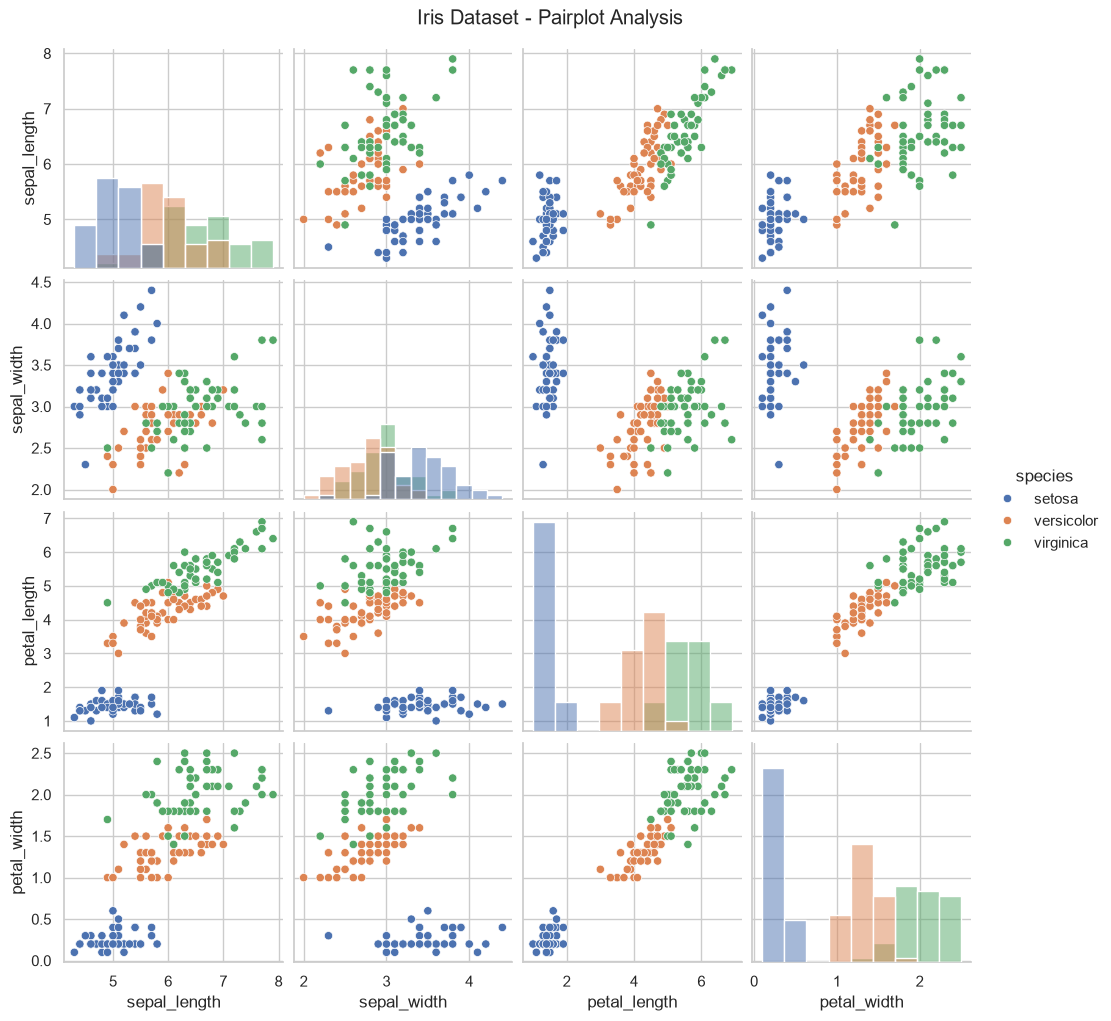

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

sns.pairplot(
    df,
    hue="species",
    diag_kind="hist"
)

plt.suptitle("Iris Dataset - Pairplot Analysis", y=1.02)

plt.show()

## Exploratory Data Analysis Findings

1. The Iris dataset contains 150 observations.
2. The dataset has four numerical features and one target variable.
3. There are three flower species: Setosa, Versicolor, and Virginica.
4. Each species contains 50 observations.
5. Missing values were checked.
6. Duplicate rows were checked.
7. Pairplot visualization was used to explore relationships
   between numerical features.

In [8]:
X = df.drop("species", axis=1)
y = df["species"]

In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [10]:
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

print("\nTraining Species Distribution:")
print(y_train.value_counts())

print("\nTesting Species Distribution:")
print(y_test.value_counts())

Training Features: (120, 4)
Testing Features: (30, 4)

Training Target: (120,)
Testing Target: (30,)

Training Species Distribution:
species
setosa        40
virginica     40
versicolor    40
Name: count, dtype: int64

Testing Species Distribution:
species
setosa        10
virginica     10
versicolor    10
Name: count, dtype: int64


## Data Splitting

The Iris dataset was divided into training and testing sets.

- 80% of the data was used for training.
- 20% of the data was used for testing.
- Stratified sampling was applied to maintain
  the original class distribution.
- Random state was set to 42 for reproducibility.

In [11]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [12]:
print("Original Training Data:")
print(X_train.head())

print("\nScaled Training Data:")
print(X_train_scaled[:5])

print("\nScaled Data Mean:")
print(X_train_scaled.mean(axis=0))

print("\nScaled Data Standard Deviation:")
print(X_train_scaled.std(axis=0))

Original Training Data:
     sepal_length  sepal_width  petal_length  petal_width
8             4.4          2.9           1.4          0.2
106           4.9          2.5           4.5          1.7
76            6.8          2.8           4.8          1.4
9             4.9          3.1           1.5          0.1
89            5.5          2.5           4.0          1.3

Scaled Training Data:
[[-1.72156775 -0.33210111 -1.34572231 -1.32327558]
 [-1.12449223 -1.22765467  0.41450518  0.6517626 ]
 [ 1.14439475 -0.5559895   0.58484978  0.25675496]
 [-1.12449223  0.11567567 -1.28894078 -1.45494479]
 [-0.40800161 -1.22765467  0.13059752  0.12508575]]

Scaled Data Mean:
[-1.36927506e-16  9.99200722e-16  1.66533454e-17  1.70234197e-16]

Scaled Data Standard Deviation:
[1. 1. 1. 1.]


## Feature Scaling

StandardScaler was used to standardize the numerical features.

- Training data was scaled using fit_transform().
- Testing data was scaled using transform().
- The scaler was fitted only on the training data
  to prevent data leakage.

Standardization transforms the features to have
approximately zero mean and unit variance.

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

In [14]:
# Create Logistic Regression Model
log_model = LogisticRegression(max_iter=200)

# Train the Model
log_model.fit(X_train_scaled, y_train)

# Make Predictions
log_predictions = log_model.predict(X_test_scaled)

In [15]:
# Create Decision Tree Model
tree_model = DecisionTreeClassifier(random_state=42)

# Train the Model
tree_model.fit(X_train_scaled, y_train)

# Make Predictions
tree_predictions = tree_model.predict(X_test_scaled)

In [16]:
print("Logistic Regression Predictions:")
print(log_predictions)

print("\nDecision Tree Predictions:")
print(tree_predictions)

print("\nActual Values:")
print(y_test.values)

Logistic Regression Predictions:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'virginica' 'virginica'
 'virginica' 'versicolor' 'setosa' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor' 'versicolor'
 'virginica' 'virginica' 'versicolor' 'setosa' 'virginica' 'setosa']

Decision Tree Predictions:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'virginica' 'virginica'
 'virginica' 'versicolor' 'setosa' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor' 'versicolor'
 'virginica' 'virginica' 'versicolor' 'setosa' 'virginica' 'setosa']

Actual Values:
<StringArray>
[    'setosa',  'virginica', 'versicolor', 'versicolor',     'setosa',
 'versicolor',     'setosa',     'setosa',  'virginica', 'versicolor',
  'virginica',  'virginica',  'virginica', 'versicolor',     'setosa',
    

In [17]:
print("Logistic Regression:")
print("Training Score:", log_model.score(X_train_scaled, y_train))
print("Testing Score:", log_model.score(X_test_scaled, y_test))

print("\nDecision Tree:")
print("Training Score:", tree_model.score(X_train_scaled, y_train))
print("Testing Score:", tree_model.score(X_test_scaled, y_test))

Logistic Regression:
Training Score: 0.9583333333333334
Testing Score: 0.9333333333333333

Decision Tree:
Training Score: 1.0
Testing Score: 0.9333333333333333


## Model Training

Two supervised machine learning classification
models were implemented.

### 1. Logistic Regression
A classification algorithm used to predict
the probability of each flower species.

### 2. Decision Tree
A tree-based classification algorithm that
uses feature-based decision rules.

Both models were trained using the scaled
training dataset and evaluated using the
scaled testing dataset.

In [18]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

In [19]:
log_accuracy = accuracy_score(y_test, log_predictions)

log_precision = precision_score(
    y_test,
    log_predictions,
    average="macro"
)

log_recall = recall_score(
    y_test,
    log_predictions,
    average="macro"
)

log_f1 = f1_score(
    y_test,
    log_predictions,
    average="macro"
)

print("Logistic Regression Performance")

print("Accuracy:", log_accuracy)
print("Precision:", log_precision)
print("Recall:", log_recall)
print("F1-Score:", log_f1)

Logistic Regression Performance
Accuracy: 0.9333333333333333
Precision: 0.9333333333333332
Recall: 0.9333333333333332
F1-Score: 0.9333333333333332


In [20]:
tree_accuracy = accuracy_score(y_test, tree_predictions)

tree_precision = precision_score(
    y_test,
    tree_predictions,
    average="macro"
)

tree_recall = recall_score(
    y_test,
    tree_predictions,
    average="macro"
)

tree_f1 = f1_score(
    y_test,
    tree_predictions,
    average="macro"
)

print("Decision Tree Performance")

print("Accuracy:", tree_accuracy)
print("Precision:", tree_precision)
print("Recall:", tree_recall)
print("F1-Score:", tree_f1)

Decision Tree Performance
Accuracy: 0.9333333333333333
Precision: 0.9333333333333332
Recall: 0.9333333333333332
F1-Score: 0.9333333333333332


In [21]:
results_df = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree"
    ],
    "Accuracy": [
        log_accuracy,
        tree_accuracy
    ],
    "Precision": [
        log_precision,
        tree_precision
    ],
    "Recall": [
        log_recall,
        tree_recall
    ],
    "F1-Score": [
        log_f1,
        tree_f1
    ]
})

print(results_df.round(4))

                 Model  Accuracy  Precision  Recall  F1-Score
0  Logistic Regression    0.9333     0.9333  0.9333    0.9333
1        Decision Tree    0.9333     0.9333  0.9333    0.9333


In [22]:
print("=== LOGISTIC REGRESSION ===")

print(
    classification_report(
        y_test,
        log_predictions,
        zero_division=0
    )
)

print("=== DECISION TREE ===")

print(
    classification_report(
        y_test,
        tree_predictions,
        zero_division=0
    )
)

=== LOGISTIC REGRESSION ===
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

=== DECISION TREE ===
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



## Model Evaluation and Benchmarking

Two classification models were evaluated using
four performance metrics:

1. Accuracy
2. Precision
3. Recall
4. F1-score

Macro averaging was used for Precision, Recall,
and F1-score to give equal importance to all
three Iris species.

A classification report was also generated
to evaluate each class individually.

The benchmark comparison table was created
to identify the better-performing model.

In [23]:
from sklearn.metrics import confusion_matrix

In [24]:
# Define class labels
class_names = ["setosa", "versicolor", "virginica"]

# Calculate confusion matrices
log_cm = confusion_matrix(
    y_test,
    log_predictions,
    labels=class_names
)

tree_cm = confusion_matrix(
    y_test,
    tree_predictions,
    labels=class_names
)

print("Logistic Regression Confusion Matrix:")
print(log_cm)

print("\nDecision Tree Confusion Matrix:")
print(tree_cm)

Logistic Regression Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]

Decision Tree Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


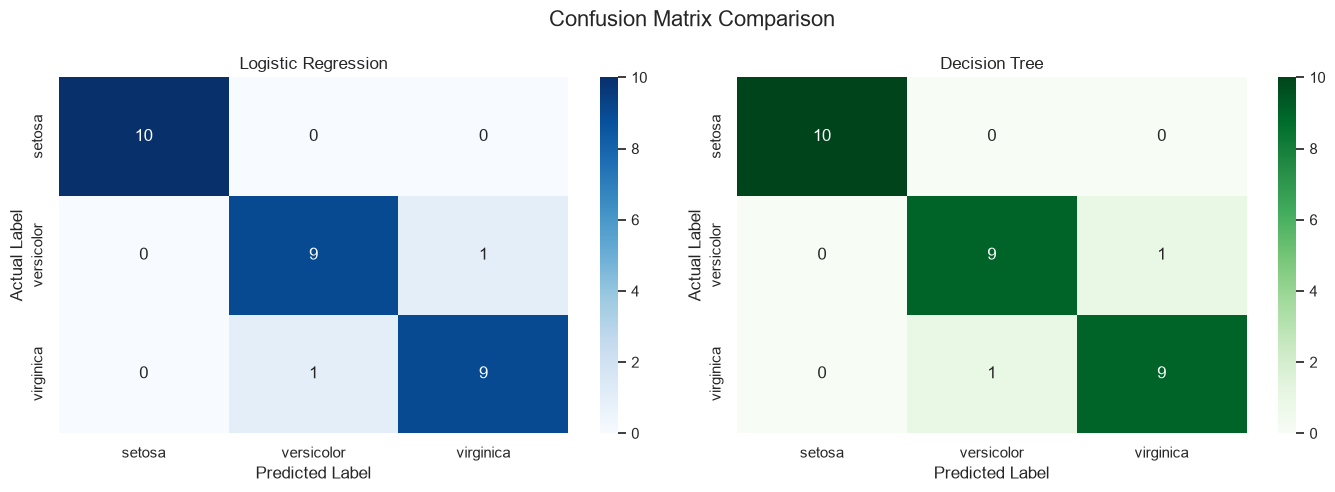

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Logistic Regression Heatmap
sns.heatmap(
    log_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    ax=axes[0]
)

axes[0].set_title("Logistic Regression")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("Actual Label")


# Decision Tree Heatmap
sns.heatmap(
    tree_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=class_names,
    yticklabels=class_names,
    ax=axes[1]
)

axes[1].set_title("Decision Tree")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("Actual Label")


plt.suptitle("Confusion Matrix Comparison", fontsize=16)

plt.tight_layout()

plt.savefig(
    "../results/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Confusion Matrix Analysis

Confusion matrices were generated for both
Logistic Regression and Decision Tree models.

Seaborn heatmaps were used to visualize
the classification results.

- Rows represent actual classes.
- Columns represent predicted classes.
- Diagonal values represent correct predictions.
- Off-diagonal values represent misclassifications.

The confusion matrices help identify which
Iris species are correctly or incorrectly
classified by each model.

In [27]:
import numpy as np

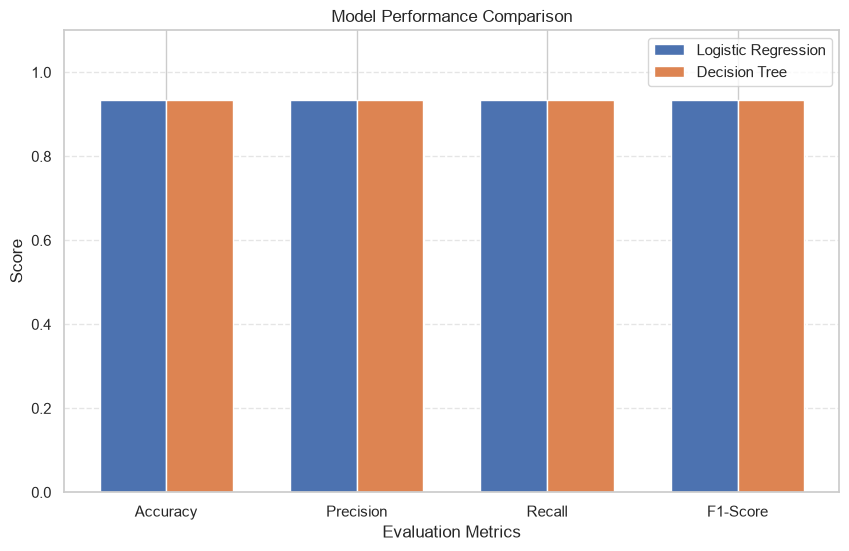

In [28]:
# Compare model performance using a bar chart

metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

x = np.arange(len(metrics))
width = 0.35

log_values = [
    accuracy_score(y_test, log_predictions),
    precision_score(y_test, log_predictions, average="macro"),
    recall_score(y_test, log_predictions, average="macro"),
    f1_score(y_test, log_predictions, average="macro")
]

tree_values = [
    accuracy_score(y_test, tree_predictions),
    precision_score(y_test, tree_predictions, average="macro"),
    recall_score(y_test, tree_predictions, average="macro"),
    f1_score(y_test, tree_predictions, average="macro")
]

plt.figure(figsize=(10, 6))

plt.bar(x - width/2, log_values, width, label="Logistic Regression")
plt.bar(x + width/2, tree_values, width, label="Decision Tree")

plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.title("Model Performance Comparison")
plt.xticks(x, metrics)
plt.ylim(0, 1.1)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.savefig("../results/model_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

### Model Comparison Findings

The bar chart compares Logistic Regression and Decision Tree using four evaluation metrics: Accuracy, Precision, Recall, and F1-Score.

Both models demonstrate their classification performance across the three Iris species. The model with higher evaluation scores generally provides better classification performance on the test dataset.

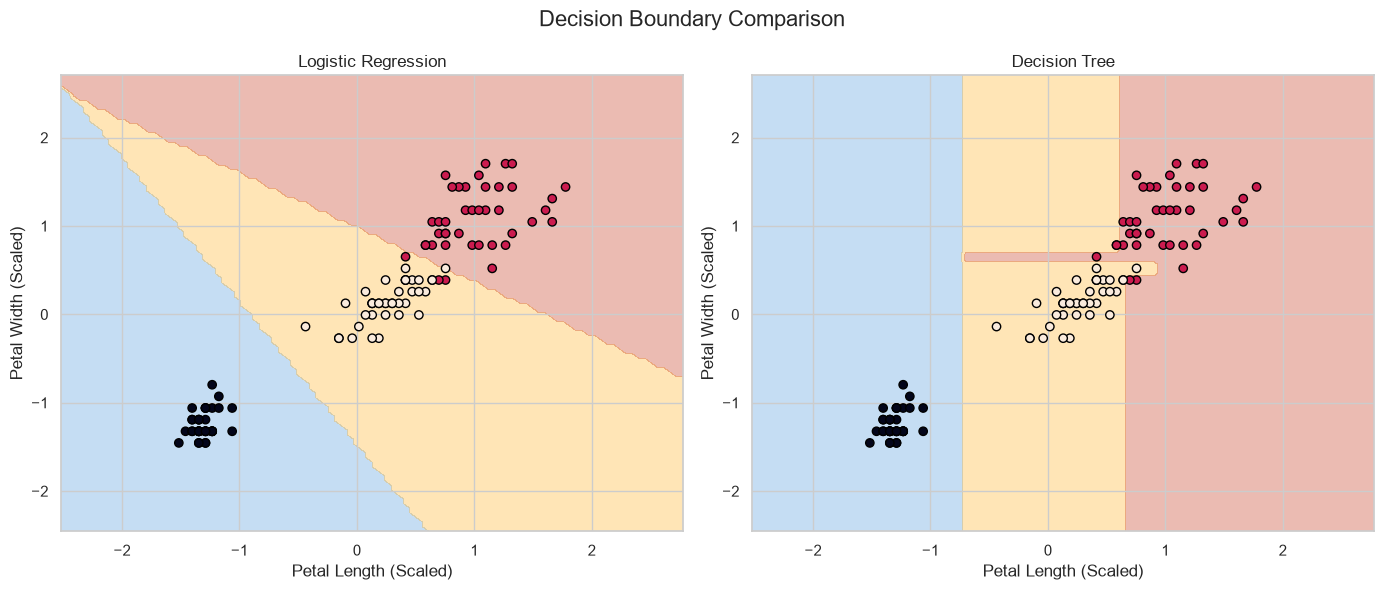

In [29]:
from sklearn.inspection import DecisionBoundaryDisplay

# Select two features for visualization
X_2d = df[["petal_length", "petal_width"]]
y_2d = df["species"]

# Split dataset
X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d,
    y_2d,
    test_size=0.2,
    random_state=42,
    stratify=y_2d
)

# Scale features
scaler_2d = StandardScaler()

X_train_2d_scaled = scaler_2d.fit_transform(X_train_2d)

# Define models
models_2d = {
    "Logistic Regression": LogisticRegression(max_iter=200),
    "Decision Tree": DecisionTreeClassifier(random_state=42)
}

# Plot decision boundaries
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, (name, model) in zip(axes, models_2d.items()):

    model.fit(X_train_2d_scaled, y_train_2d)

    DecisionBoundaryDisplay.from_estimator(
        model,
        X_train_2d_scaled,
        ax=ax,
        response_method="predict",
        alpha=0.3
    )

    ax.scatter(
        X_train_2d_scaled[:, 0],
        X_train_2d_scaled[:, 1],
        c=pd.factorize(y_train_2d)[0],
        edgecolor="black"
    )

    ax.set_title(name)
    ax.set_xlabel("Petal Length (Scaled)")
    ax.set_ylabel("Petal Width (Scaled)")

plt.suptitle("Decision Boundary Comparison", fontsize=16)
plt.tight_layout()

plt.savefig(
    "../results/decision_boundary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Decision Boundary Analysis

Decision boundary visualization shows how Logistic Regression and Decision Tree classify Iris flowers using petal length and petal width.

Logistic Regression creates relatively smooth decision boundaries, while Decision Tree creates rule-based rectangular regions.

This visualization helps us understand how different classification algorithms separate the three Iris species.

In [30]:
print("FINAL MODEL COMPARISON")
print("=" * 50)

print(results_df)

best_model = results_df.loc[
    results_df["F1-Score"].idxmax(), "Model"
]

print("\nBest Performing Model:", best_model)

FINAL MODEL COMPARISON
                 Model  Accuracy  Precision    Recall  F1-Score
0  Logistic Regression  0.933333   0.933333  0.933333  0.933333
1        Decision Tree  0.933333   0.933333  0.933333  0.933333

Best Performing Model: Logistic Regression


## Final Conclusion

In this project, we developed a multi-class classification pipeline using the Iris dataset.

The project included:

1. Data loading and exploratory data analysis.
2. Data preprocessing and feature scaling.
3. Training Logistic Regression and Decision Tree models.
4. Evaluating models using Accuracy, Precision, Recall, and F1-Score.
5. Visualizing confusion matrices and model performance.
6. Comparing decision boundaries.

The evaluation results show the strengths of each classification algorithm. The best-performing model was selected based on its F1-Score.

This project demonstrates a complete machine learning classification workflow using Python and Scikit-learn.